# Fire history for Eastern Suburb Banksia Shrubs

## Load libraries and functions

In [1]:
import pyprojroot
#import os
#from pathlib import Path
#import sys
#import json
#import requests
#import zipfile,  io
#import geojson 
import pandas as pd
import geopandas as gpd
import re
import numpy as np
from matplotlib import pyplot as plt
from datetime import datetime

## Relative paths and data folder

In [2]:
repodir = pyprojroot.find_root(pyprojroot.has_dir(".git"))

In [3]:
gisdata_dir = repodir / 'gisdata' / 'NSW'

## Load GIS data

In [4]:
firehistory = gpd.read_file(gisdata_dir / "NPWSFireHistory.shp")

In [5]:
firehistory.head()

,FireType,FireName,FireNo,Label,StartDate,EndDate,AreaHa,PerimeterM,d_FireType,geometry
0,2,None,None,1970-71 Prescribed Burn,NaT,NaT,299.985464,8615.637120,Prescribed Burn,"POLYGON ((152.77796 -31.63806, 152.77822 -31.6..."
1,2,None,70/161,1970-71 Prescribed Burn,NaT,NaT,309.025645,20657.633993,Prescribed Burn,"POLYGON ((151.50894 -31.98245, 151.50911 -31.9..."
2,2,None,None,1970-71 Prescribed Burn,1970-07-01,NaT,13.600002,1999.487701,Prescribed Burn,"POLYGON ((153.14728 -30.17573, 153.14721 -30.1..."
3,2,None,0,1971-72 Prescribed Burn,1971-07-01,NaT,58.994371,5312.210152,Prescribed Burn,"POLYGON ((152.2127 -32.24101, 152.21272 -32.24..."
4,2,None,0,1971-72 Prescribed Burn,1971-07-01,NaT,383.155154,20564.602731,Prescribed Burn,"POLYGON ((152.1928 -32.2418, 152.19281 -32.241..."


In [6]:
ss0 = firehistory.Label != firehistory.Label
ss1 = firehistory.StartDate != firehistory.StartDate
ss2 = firehistory.EndDate != firehistory.EndDate
print("No label %s, No start date %s, No end date %s" % 
      (sum(ss0), sum(ss1), sum(ss2)))
print("No dates %s, Only end date %s, Only start date %s" % 
      (sum(ss1 & ss2), sum(ss1 & ~ss2), sum(~ss1 & ss2)))

No label 0, No start date 15340, No end date 20020
No dates 15009, Only end date 331, Only start date 5011


In [7]:
bestdate =  list()
sourcedate = list()
format_string = "%Y-%m-%d"
for idx, row in firehistory.iterrows():
    if row.StartDate == row.StartDate:
        bestdate.append(row.StartDate.date())
        sourcedate.append("Start date")
    elif row.EndDate == row.EndDate:
        bestdate.append(row.EndDate.date())
        sourcedate.append("End date")
    else:
        date_string = "%s-12-31" % re.findall(r'\d+', row.Label)[0]
        bestdate.append(datetime.strptime(date_string, format_string).date())
        sourcedate.append("Pseudo date")

In [8]:
from collections import Counter
Counter(sourcedate)

Counter({'Start date': 21667, 'Pseudo date': 15009, 'End date': 331})

In [9]:
firehistory['best_date']=bestdate
firehistory['source_date']=sourcedate

In [10]:
firehistory.loc[firehistory.source_date=='End date']

,FireType,FireName,FireNo,Label,StartDate,EndDate,AreaHa,PerimeterM,d_FireType,geometry,best_date,source_date
5792,1,Upper Cordeaux,None,2000-01 Wildfire,NaT,2000-07-08,0.021619,57.782665,Wildfire,"POLYGON ((150.78625 -34.43185, 150.78624 -34.4...",2000-07-08,End date
5793,1,Upper Cordeaux,None,2000-01 Wildfire,NaT,2000-08-19,0.032489,63.955681,Wildfire,"POLYGON ((150.80933 -34.41156, 150.80933 -34.4...",2000-08-19,End date
5794,1,None,None,2000-01 Wildfire,NaT,2000-09-20,2.568208,628.057727,Wildfire,"POLYGON ((150.8164 -34.40937, 150.8164 -34.409...",2000-09-20,End date
5795,1,None,None,2000-01 Wildfire,NaT,2000-09-20,0.568572,313.805132,Wildfire,"POLYGON ((150.8164 -34.40937, 150.81631 -34.40...",2000-09-20,End date
5796,1,None,None,2000-01 Wildfire,NaT,2000-12-26,2.568179,628.036210,Wildfire,"POLYGON ((150.8164 -34.40937, 150.8164 -34.409...",2000-12-26,End date
...,...,...,...,...,...,...,...,...,...,...,...,...
28964,1,Mahogany Drive,None,2014-15 Wildfire,NaT,2014-08-03,76.293432,3750.765502,Wildfire,"POLYGON ((153.12626 -29.76998, 153.12791 -29.7...",2014-08-03,End date
30001,1,None,None,1903-04 Wildfire,NaT,1903-12-30,96.859837,5450.782888,Wildfire,"MULTIPOLYGON (((149.95888 -36.54242, 149.959 -...",1903-12-30,End date
30453,2,Coolangubra East HAMZ,None,2003-04 Prescribed Burn,NaT,2004-04-30,8243.549764,81700.270267,Prescribed Burn,"MULTIPOLYGON (((149.5341 -36.95988, 149.53805 ...",2004-04-30,End date
30719,1,Buttai Fire,None,2001-02 Wildfire,NaT,2001-12-27,2.029673,540.720329,Wildfire,"POLYGON ((151.56753 -32.83401, 151.56769 -32.8...",2001-12-27,End date


In [11]:
TECdist = gpd.read_file(gisdata_dir / "Threatened_ecological_communities_GreaterSydney_2024.shp")

In [12]:
TECdist.groupby('POTENTIAL_').agg({'Shape_Area':{'count','sum'}})

Shape_Area       
                  sum  count
POTENTIAL_                  
TEC_ABW      0.000161     29
TEC_BGHF     0.000773   1832
TEC_BMBF     0.004321    549
TEC_BMSCF    0.000099     28
TEC_BMSw     0.003103   1885
TEC_BSF      0.000022     20
TEC_CPW      0.021418  12412
TEC_CRCIF    0.004934   1541
TEC_CSGW     0.003736    815
TEC_CSW      0.000540    204
TEC_CSm      0.000294   1058
TEC_CUS      0.001284   1117
TEC_DFEC     0.000389    339
TEC_EBSF     0.000013     38
TEC_ESBS     0.000499    458
TEC_FWCF     0.001065    353
TEC_HC       0.000018      2
TEC_KDF      0.000096     76
TEC_LR       0.000092    102
TEC_MPS      0.000144     47
TEC_MSSF     0.000004      1
TEC_MSW      0.001323    853
TEC_OCSF     0.000063     13
TEC_PWSGF    0.000481    215
TEC_RFEFCF   0.010925   4887
TEC_SFW      0.000123    217
TEC_SOFF     0.000887   1622
TEC_SSFCF    0.000399    285
TEC_SSSF     0.000181     30
TEC_SSTF     0.019509   6685
TEC_STIF     0.003135   3632
TEC_SVCGF    0.000040     87
TEC_TGSCH    0.000014     33
TEC_TSC      0.000044      1
TEC_WSDR     0.000563    607

## Outline of analysis

This is the plan
- [x] select ESBS polygons
- [x] select random points inside polygons (1, 5, 10 per polygon)
- [ ] for each point use a random sampling date,
- [x] intersect points with firehistory
- [x] aggregate by points and calculate number of fires, earliests and latest fire year
- [x] histograms of these
- [ ] calculate intervals from sampling date to last fire and penultimate fire
- [ ] histograms of these

### First step

Select random points within the selected ESBS polygons and add a random sampling date for each point

We will need this function to generate random dates:

In [35]:
def random_dates(start, end, n, unit='D', seed=None):
    if not seed:  # from piR's answer
        np.random.seed(0)

    ndays = (end - start).days + 1
    final_date = pd.to_timedelta(np.random.rand(n) * ndays, unit=unit) + start
    return final_date.date


And we need to set up a random seed and starting and end dates

In [36]:
np.random.seed(0)

In [37]:
start = pd.to_datetime('2015-01-01')
end = pd.to_datetime('2025-01-01')

In [38]:
pts01 = gpd.GeoDataFrame(geometry=TECdist.loc[TECdist.POTENTIAL_=="TEC_ESBS"].sample_points(size=1), 
                 crs= TECdist.crs)

In [39]:
pts01['sampling date']=random_dates(start, end, pts01.shape[0])

In [40]:
pts05 = gpd.GeoDataFrame(geometry=TECdist.loc[TECdist.POTENTIAL_=="TEC_ESBS"].sample_points(size=5), 
                 crs= TECdist.crs).explode(ignore_index=True)


In [41]:
pts05['sampling date']=random_dates(start, end, pts05.shape[0])

In [42]:
pts05.head()

,geometry,sampling date
0,POINT (151.2067 -34.03566),2020-06-28
1,POINT (151.20743 -34.03714),2022-02-26
2,POINT (151.20844 -34.03479),2021-01-11
3,POINT (151.20856 -34.03478),2020-06-14
4,POINT (151.20881 -34.03405),2019-03-29


### Second step
Intersect points with fire history data and calculate min and max year for each fire event

In [57]:
fh_ESBS_05 = gpd.sjoin(pts05,firehistory,how='left')

In [58]:
fh_ESBS_01 = gpd.sjoin(pts01,firehistory,how='left')

In [65]:
fh_ESBS_01.head()

,geometry,sampling date,index_right,FireType,FireName,FireNo,Label,StartDate,EndDate,AreaHa,PerimeterM,d_FireType,best_date,source_date
16569,POINT (151.20864 -34.03554),2020-06-28,5756.0,1.0,Tabbagai fire,smt/00/018,2000-01 Wildfire,2000-10-03,NaT,305.084912,11272.478011,Wildfire,2000-10-03,Start date
16569,POINT (151.20864 -34.03554),2020-06-28,30919.0,1.0,"Captain Cook Dr, Kurnell, Sutherland",17090372496,2017-18 Wildfire,2017-09-03,2017-09-10,352.561496,9927.604047,Wildfire,2017-09-03,Start date
16570,POINT (151.20424 -34.03453),2022-02-26,5756.0,1.0,Tabbagai fire,smt/00/018,2000-01 Wildfire,2000-10-03,NaT,305.084912,11272.478011,Wildfire,2000-10-03,Start date
16570,POINT (151.20424 -34.03453),2022-02-26,30919.0,1.0,"Captain Cook Dr, Kurnell, Sutherland",17090372496,2017-18 Wildfire,2017-09-03,2017-09-10,352.561496,9927.604047,Wildfire,2017-09-03,Start date
16571,POINT (151.24972 -33.98942),2021-01-11,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN


### Third step
Aggregate by points and calculate number of fires, earliests and latest fire year.

In [60]:
aggfuncs = {'index_right': 'count', 'Label':'count', 
            'best_date': 'min', 'sampling date': 'max'}
fh_agg_01 = fh_ESBS_01.groupby(level=0).agg(aggfuncs)
fh_agg_05 = fh_ESBS_05.groupby(level=0).agg(aggfuncs)

In [61]:
fh_agg_01

,index_right,Label,best_date,sampling date
16569,2,2,2000-10-03,2020-06-28
16570,2,2,2000-10-03,2022-02-26
16571,0,0,NaN,2021-01-11
16572,0,0,NaN,2020-06-14
16573,0,0,NaN,2019-03-29
...,...,...,...,...
38541,2,2,1995-04-01,2016-01-22
38542,0,0,NaN,2024-07-06
38543,3,3,1982-12-31,2017-05-02
39603,1,1,2008-12-31,2021-11-25


### Fourth step
Calculate and display histograms for nr. of fires, min and max year of fire events.

In [62]:
def get_value_counts(df):
    xs = df.index_right.value_counts().sort_index()
    ini=[x for x in xs.index]
    bins=[x-0.5 for x in xs.index] + [(max(ini)+0.5)]
    vals=[int(x) for x in xs.values]
    return((ini,bins,vals))

(array([283.,  68.,  50.,  30.,  20.,   6.,   1.]),
 array([-0.5,  0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5]),
 <BarContainer object of 7 artists>)

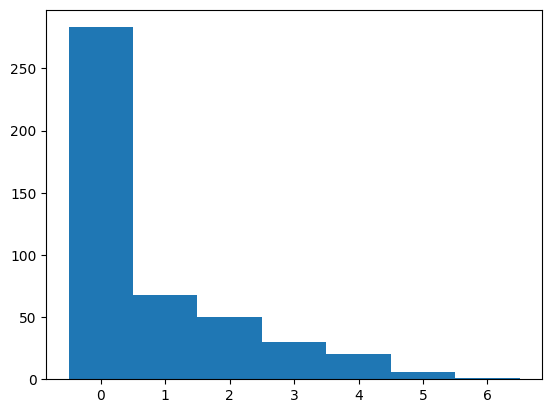

In [63]:
ini, bins, vals = get_value_counts(fh_agg_01)
plt.hist(ini, bins, weights=vals)

(array([1402.,  375.,  257.,  121.,  104.,   23.,    8.]),
 array([-0.5,  0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5]),
 <BarContainer object of 7 artists>)

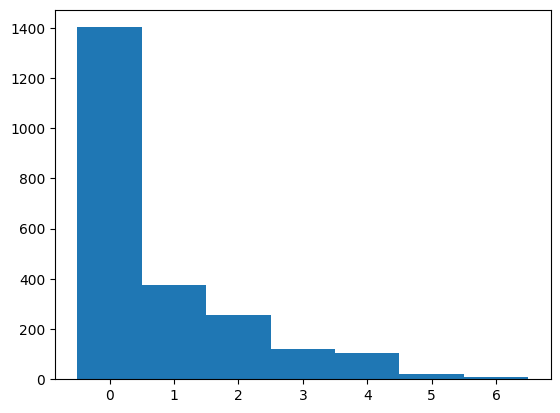

In [64]:
ini, bins, vals = get_value_counts(fh_agg_05)
plt.hist(ini, bins, weights=vals)

In [77]:
ss = fh_agg_01.best_date == fh_agg_01.best_date

In [82]:
for j in fh_agg_01.loc[ss,'best_date']:
    type(j)
type(j)

datetime.date

In [78]:
counts1, bins1 = np.histogram(
    fh_agg_01.loc[ss,'best_date']
)
#counts2, bins2 = np.histogram(
#    fh_agg_01.loc[~np.isnan(fh_agg_01.best_date),'sampling date']
#)

TypeError: ufunc 'isfinite' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

(array([ 3.,  4.,  2., 27., 14.,  5., 13., 19., 73., 18.]),
 array([1977. , 1981.8, 1986.6, 1991.4, 1996.2, 2001. , 2005.8, 2010.6,
        2015.4, 2020.2, 2025. ]),
 <BarContainer object of 10 artists>)

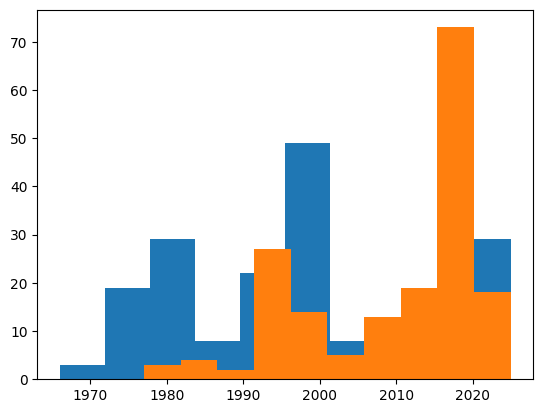

In [196]:
plt.hist(bins1[:-1], bins1, weights=counts1)
plt.hist(bins2[:-1], bins2, weights=counts2)

In [197]:
fh_ESBS_01.groupby(level=0)[['MinYear',	'MaxYear']].aggregate(lambda x: list(x))

,MinYear,MaxYear
16569,"[2000.0, 2017.0]","[2000.0, 2017.0]"
16570,[2000.0],[2000.0]
16571,[nan],[nan]
16572,[nan],[nan]
16573,[nan],[nan]
...,...,...
38541,"[1995.0, 2016.0]","[1994.0, 2015.0]"
38542,[nan],[nan]
38543,"[2000.0, 1982.0]","[2000.0, 1982.0]"
39603,[2008.0],[2008.0]
